## Evento Evaluativo 4 - Machine Learning

Diego Alejandro Gómez Carmona

# 1. Descripción del problema

Este DataSet se basa en predecir cuales son las especies de árbol predominante en parcelas de tierra de 30x30 metros en el bosque nacional Roosevelt, las cuales se denominan como cubierta forestal dominante, y en este dataset son 7. Usando variables cartografícas y topografícas, esto permite mantener conocimiento acerca de los ecosistemas del bosque nacional sin tener que depender de expediciones que tienen altos costos y sin tener las limitaciones de las imagenes satelitales que debido al clima y resolución indicen a fallos. Esto sirve para por ejemplo prevenir incendios, conservar los hábitats, reforestación o monitorear el cambio climatico.

Preguntas:
1. Cómo están distribuidas las 7 clases y qué tan desbalanceadas están?
2. Qué variables separan mejor los tipos de cobertura?
3. Qué relación hay entre el área silvestre y el tipo de suelo con la cobertura?
4. Qué modelo supervisado clasifica mejor y qué clases se confunden?
5. Hace falta usar todo el dataset o con una muestra es suficiente?
6. Sin usar la etiqueta, se pueden encontrar grupos y se parecen a los tipos de cobertura?

In [ ]:
%pip install ucimlrepo

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## 2. Exploración de los datos
## Carga del dataset


In [3]:
NUMERICAS = ['Elevation', 'Aspect', 'Slope',
             'Horizontal_Distance_To_Hydrology', 'Vertical_Distance_To_Hydrology',
             'Horizontal_Distance_To_Roadways', 'Hillshade_9am', 'Hillshade_Noon',
             'Hillshade_3pm', 'Horizontal_Distance_To_Fire_Points']
AREAS = ['Wilderness_Area_' + str(i) for i in range(1, 5)]
SUELOS = ['Soil_Type_' + str(i) for i in range(1, 41)]
VARIABLES = NUMERICAS + AREAS + SUELOS

from ucimlrepo import fetch_ucirepo

covertype = fetch_ucirepo(id=31)
df = pd.concat([covertype.data.features, covertype.data.targets], axis=1)

df.columns = df.columns.str.replace(r'(Wilderness_Area|Soil_Type)_?(\d+)', r'\1_\2', regex=True)
df = df[VARIABLES + ['Cover_Type']]
df.head()

,Elevation,Aspect,Slope,Horizontal_Distance_To_Hydrology,Vertical_Distance_To_Hydrology,Horizontal_Distance_To_Roadways,Hillshade_9am,Hillshade_Noon,Hillshade_3pm,Horizontal_Distance_To_Fire_Points,...,Soil_Type_32,Soil_Type_33,Soil_Type_34,Soil_Type_35,Soil_Type_36,Soil_Type_37,Soil_Type_38,Soil_Type_39,Soil_Type_40,Cover_Type
0,2596,51,3,258,0,510,221,232,148,6279,...,0,0,0,0,0,0,0,0,0,5
1,2590,56,2,212,-6,390,220,235,151,6225,...,0,0,0,0,0,0,0,0,0,5
2,2804,139,9,268,65,3180,234,238,135,6121,...,0,0,0,0,0,0,0,0,0,2
3,2785,155,18,242,118,3090,238,238,122,6211,...,0,0,0,0,0,0,0,0,0,2
4,2595,45,2,153,-1,391,220,234,150,6172,...,0,0,0,0,0,0,0,0,0,5


In [4]:
# nombres de las clases según covtype.info
CLASES = {1: 'Picea/Abeto', 2: 'Pino contorta', 3: 'Pino ponderosa', 4: 'Álamo/Sauce',
          5: 'Álamo temblón', 6: 'Abeto Douglas', 7: 'Krummholz'}

## Análisis inicial

Jorge Elias Builes Chavarria

In [5]:
print("numero de filas y columnas:", df.shape)
df.info()

numero de filas y columnas: (581012, 55)
<class 'pandas.DataFrame'>
RangeIndex: 581012 entries, 0 to 581011
Data columns (total 55 columns):
 #   Column                              Non-Null Count   Dtype
---  ------                              --------------   -----
 0   Elevation                           581012 non-null  int64
 1   Aspect                              581012 non-null  int64
 2   Slope                               581012 non-null  int64
 3   Horizontal_Distance_To_Hydrology    581012 non-null  int64
 4   Vertical_Distance_To_Hydrology      581012 non-null  int64
 5   Horizontal_Distance_To_Roadways     581012 non-null  int64
 6   Hillshade_9am                       581012 non-null  int64
 7   Hillshade_Noon                      581012 non-null  int64
 8   Hillshade_3pm                       581012 non-null  int64
 9   Horizontal_Distance_To_Fire_Points  581012 non-null  int64
 10  Wilderness_Area_1                   581012 non-null  int64
 11  Wilderness_Area_2     

## Nulos y duplicados
Se revisó la calidad básica de los datos. El dataset tiene 581.012 filas y 55 columnas (54 variables más la cobertura) y no se encontraron valores nulos ni filas duplicadas. Tampoco hay filas con las mismas variables pero distinta clase, es decir, no hay registros contradictorios. Por eso no hace falta imputar ni eliminar nada en esta etapa.

In [6]:
print("Nulos:", df.isna().sum().sum())
print("Filas duplicadas:", df.duplicated().sum())
print("Filas con las mismas variables pero distinta clase:",
      df.duplicated(subset=VARIABLES).sum() - df.duplicated().sum())

Nulos: 0


Filas duplicadas: 0


Filas con las mismas variables pero distinta clase: 0


## Variables binarias
Área silvestre y tipo de suelo vienen en columnas de 0 y 1. Se revisa que cada fila tenga un solo 1 en cada grupo.

Todas las filas tienen exactamente un 1 en las 4 columnas de área silvestre y exactamente un 1 en las 40 columnas de tipo de suelo. Es decir, cada registro pertenece a una sola área y a un solo suelo. Estas variables ya vienen codificadas en formato 0 y 1 (one-hot), así que no hace falta volver a codificarlas: se pueden usar directamente en los modelos.

In [7]:
print(df[AREAS].sum(axis=1).value_counts())
print(df[SUELOS].sum(axis=1).value_counts())

1    581012
Name: count, dtype: int64
1    581012
Name: count, dtype: int64


In [8]:
# columnas para el EDA: área y suelo en una sola columna
df['area'] = df[AREAS].idxmax(axis=1)
df['suelo'] = df[SUELOS].idxmax(axis=1)

## Variable objetivo
El dataset está muy desbalanceado. Las clases 2 y 1 concentran el 48,76 % y el 36,46 % de los registros, es decir, más del 85 % del total. Las clases minoritarias son la 4 (0,47 %, solo 2.747 filas), la 5 (1,63 %), la 6 (2,99 %) y la 7 (3,53 %); la 3 tiene el 6,15 %. La clase más grande tiene unas 103 veces más registros que la más pequeña. Por eso el accuracy solo no basta: un modelo que siempre responda la clase 2 acertaría cerca del 48,8 % sin aprender nada, y además fallaría en todas las clases pequeñas. Se necesita una métrica que mire cada clase por igual, como el F1 macro.

Cover_Type
1    211840
2    283301
3     35754
4      2747
5      9493
6     17367
7     20510
Name: count, dtype: int64
Cover_Type
1    36.46
2    48.76
3     6.15
4     0.47
5     1.63
6     2.99
7     3.53
Name: count, dtype: float64


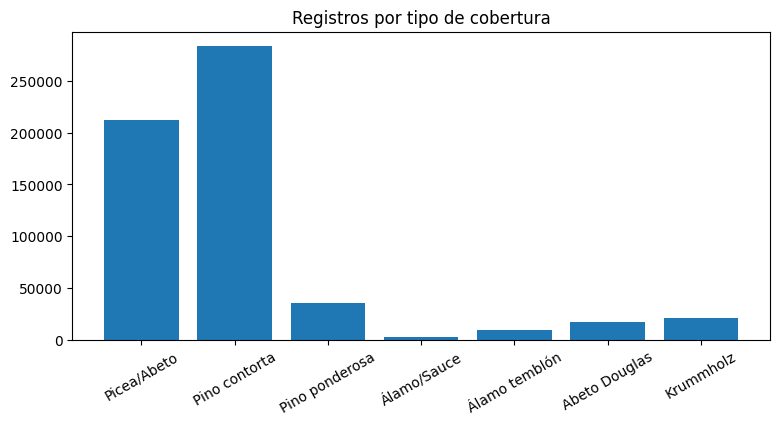

In [9]:
conteo = df['Cover_Type'].value_counts().sort_index()
print(conteo)
print((conteo / len(df) * 100).round(2))

plt.figure(figsize=(9, 4))
plt.bar(conteo.index.map(CLASES), conteo.values)
plt.title('Registros por tipo de cobertura')
plt.xticks(rotation=30)
plt.show()

## Estadística descriptiva

In [10]:
df[NUMERICAS].describe().T

,count,mean,std,min,25%,50%,75%,max
Elevation,581012.0,2959.365301,279.984734,1859.0,2809.0,2996.0,3163.0,3858.0
Aspect,581012.0,155.656807,111.913721,0.0,58.0,127.0,260.0,360.0
Slope,581012.0,14.103704,7.488242,0.0,9.0,13.0,18.0,66.0
Horizontal_Distance_To_Hydrology,581012.0,269.428217,212.549356,0.0,108.0,218.0,384.0,1397.0
Vertical_Distance_To_Hydrology,581012.0,46.418855,58.295232,-173.0,7.0,30.0,69.0,601.0
Horizontal_Distance_To_Roadways,581012.0,2350.146611,1559.254870,0.0,1106.0,1997.0,3328.0,7117.0
Hillshade_9am,581012.0,212.146049,26.769889,0.0,198.0,218.0,231.0,254.0
Hillshade_Noon,581012.0,223.318716,19.768697,0.0,213.0,226.0,237.0,254.0
Hillshade_3pm,581012.0,142.528263,38.274529,0.0,119.0,143.0,168.0,254.0
Horizontal_Distance_To_Fire_Points,581012.0,1980.291226,1324.195210,0.0,1024.0,1710.0,2550.0,7173.0


## Distribución de las variables numéricas
Las variables numéricas no siguen una distribución normal. Las distancias a hidrología, a vías y a puntos de fuego, y también la pendiente, tienen asimetría hacia la derecha: la mayoría de los valores son pequeños y hay una cola larga de valores altos (hasta 1.397 m en hidrología y más de 7.000 m en vías y fuego). Los sombreados de las 9 am y del mediodía son lo contrario: casi todos los valores son altos (medianas de 218 y 226) y la cola va hacia 0. La elevación se concentra entre unos 2.800 y 3.160 m, con una cola hacia las zonas bajas. Aspect es una variable circular (0° y 360° son lo mismo) y hay más registros hacia el norte y el este que hacia el sur y el oeste.

Además, las escalas son muy distintas: la elevación va de 1.859 a 3.858, las distancias llegan a unos 7.000, los sombreados van de 0 a 254 y la pendiente de 0 a 66. Por eso hay que estandarizar las variables antes de usar modelos basados en distancias o en gradientes, como KNN, regresión logística y K-Means. El Random Forest no lo necesita.

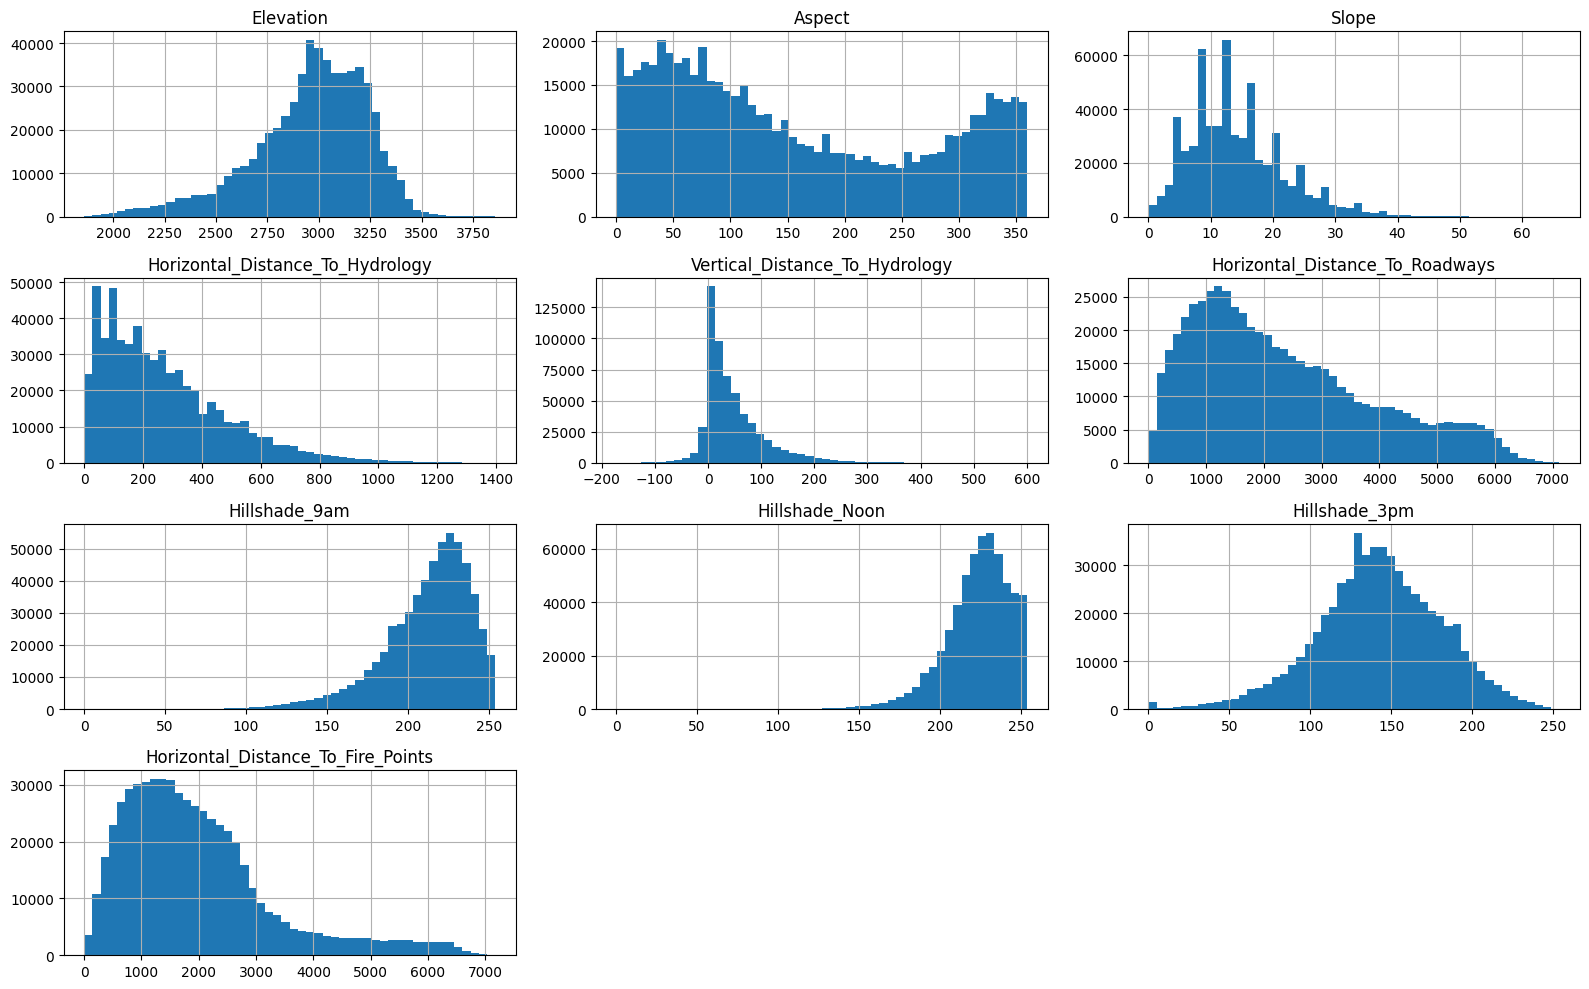

In [11]:
df[NUMERICAS].hist(bins=50, figsize=(16, 10))
plt.tight_layout()
plt.show()

## Valores atípicos
Se cuentan los valores por fuera de 1.5 veces el rango intercuartílico.

Con el criterio de 1,5 veces el rango intercuartílico, las variables con más atípicos son la distancia vertical a hidrología (31.463 valores, 5,42 %) y la distancia a puntos de fuego (31.157, 5,36 %). Les siguen los sombreados de las 9 am (3,00 %) y del mediodía (2,70 %), la elevación (2,68 %), la pendiente (2,64 %) y la distancia horizontal a hidrología (2,51 %). Aspect no tiene ninguno, y la distancia a vías casi no tiene (0,12 %).

No se eliminan porque no son errores: son medidas reales del terreno. Por ejemplo, hay 55.143 registros (9,49 %) con distancia vertical negativa, que corresponden a puntos que están por debajo del nivel del agua más cercana, algo normal en esta zona. Además, estos valores extremos son los que pueden ayudar a distinguir algunas coberturas, y eliminarlos significaría perder información. Los modelos que se usan (sobre todo los de árboles) son poco sensibles a ellos, y en los que sí lo son se estandarizan las variables.

In [12]:
for col in NUMERICAS:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    atipicos = ((df[col] < q1 - 1.5 * iqr) | (df[col] > q3 + 1.5 * iqr)).sum()
    print(f"{col}: {atipicos} atípicos ({atipicos / len(df):.2%})")

print("Distancias verticales negativas:", (df['Vertical_Distance_To_Hydrology'] < 0).sum())

Elevation: 15569 atípicos (2.68%)
Aspect: 0 atípicos (0.00%)
Slope: 15316 atípicos (2.64%)
Horizontal_Distance_To_Hydrology: 14557 atípicos (2.51%)
Vertical_Distance_To_Hydrology: 31463 atípicos (5.42%)
Horizontal_Distance_To_Roadways: 669 atípicos (0.12%)
Hillshade_9am: 17433 atípicos (3.00%)
Hillshade_Noon: 15672 atípicos (2.70%)
Hillshade_3pm: 7832 atípicos (1.35%)
Horizontal_Distance_To_Fire_Points: 31157 atípicos (5.36%)
Distancias verticales negativas: 55143


## Variables numéricas según la cobertura
La variable que mejor separa las coberturas es la elevación. Las medianas van de 2.231 m en la clase 4 y 2.404 m en la clase 3 hasta 3.146 m en la clase 1 y 3.363 m en la clase 7, y una medida de cuánto se diferencian los grupos da 0,62 para la elevación contra menos de 0,10 para la distancia a vías, la distancia a puntos de fuego y la pendiente.

Aun así, ninguna variable separa las siete clases por sí sola. Las clases 1 y 2 se solapan bastante en elevación (medianas de 3.146 y 2.935 m), y las clases 3 y 6 son casi iguales (2.404 y 2.428 m). La clase 5 queda en una zona intermedia que también se cruza con la 2. Con las otras variables pasa algo parecido: las clases 3, 4 y 6 están más cerca de las vías (medianas de 850 a 950 m) y en terrenos más empinados (pendiente mediana de 19 a 21) que las clases 1, 2 y 7 (vías a 2.000-2.650 m y pendiente de 12 a 13), pero dentro de cada grupo se parecen mucho entre sí; por ejemplo, las clases 1 y 2 tienen casi la misma distancia a puntos de fuego (1.825 y 1.846 m).

Esto indica que hay que combinar varias variables y que las parejas 1-2 y 3-6 probablemente serán las más difíciles de distinguir para los modelos.

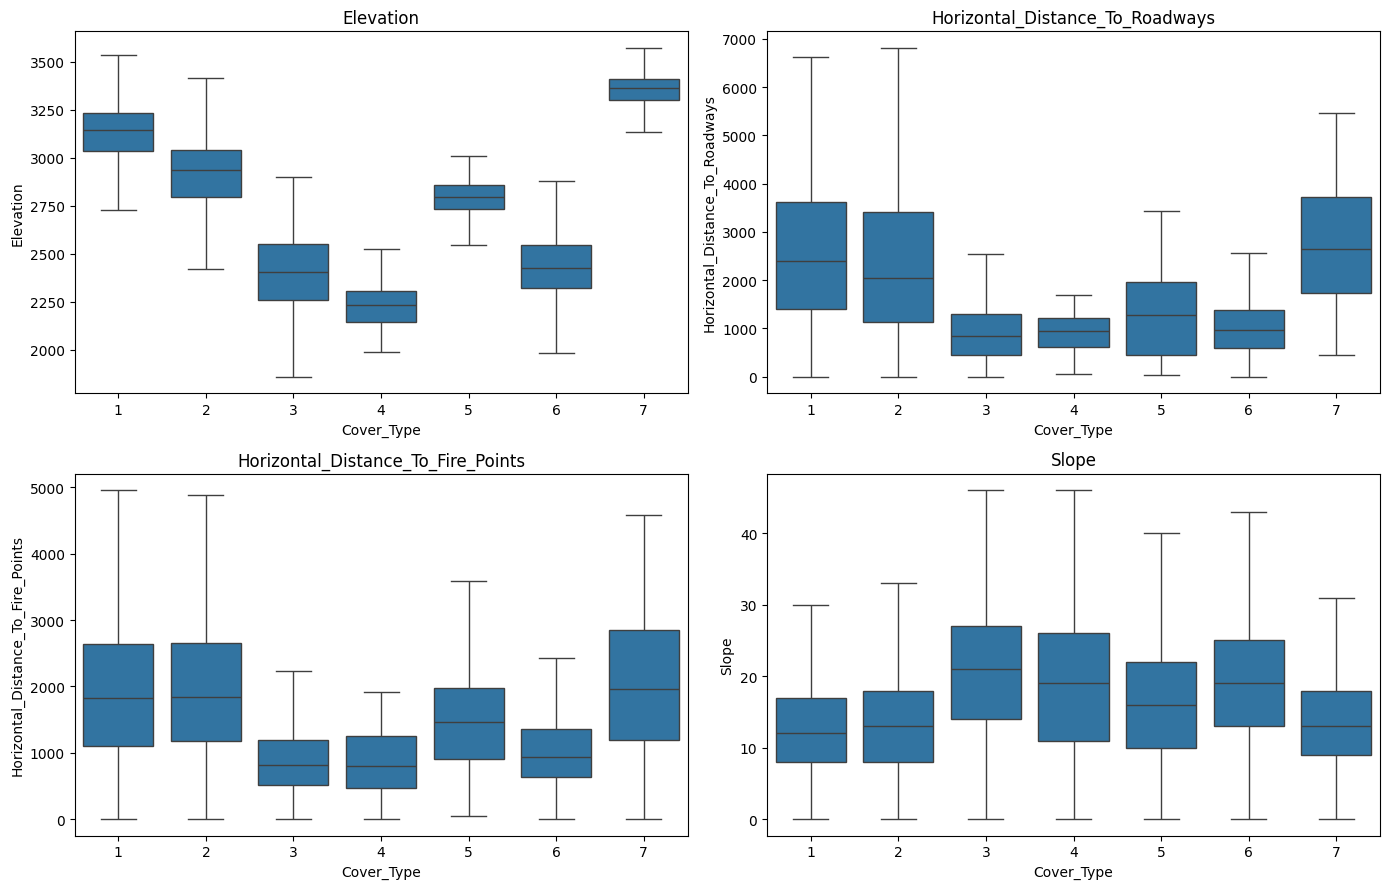

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, col in zip(axes.flat, ['Elevation', 'Horizontal_Distance_To_Roadways',
                               'Horizontal_Distance_To_Fire_Points', 'Slope']):
    sns.boxplot(data=df, x='Cover_Type', y=col, showfliers=False, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

## Área silvestre y cobertura
Las áreas 1 y 3 concentran casi el 90 % de los registros (260.796 y 253.364), mientras que las áreas 4 y 2 son pequeñas (36.968 y 29.884). En las áreas 1, 2 y 3 dominan las clases 1 y 2 (por ejemplo, en el área 1 son el 40,5 % y el 56,1 %), y la clase 7 solo aparece en esas tres áreas. El área 4 es muy distinta: está formada sobre todo por la clase 3 (58,0 %) y la clase 6 (26,3 %), con algo de clase 2 (8,2 %) y clase 4 (7,4 %), y no tiene clases 1, 5 ni 7. La clase 4 aparece únicamente en el área 4, y las clases 3 y 6 solo en las áreas 3 y 4. Esto muestra que el área silvestre aporta información útil, porque con solo saber el área ya se descartan varias coberturas.

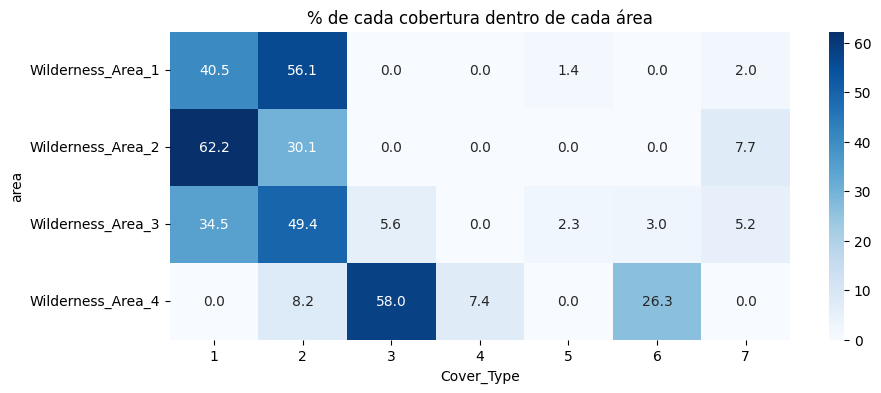

In [14]:
tabla_area = pd.crosstab(df['area'], df['Cover_Type'], normalize='index') * 100
plt.figure(figsize=(10, 4))
sns.heatmap(tabla_area, annot=True, fmt='.1f', cmap='Blues')
plt.title('% de cada cobertura dentro de cada área')
plt.show()

## Tipos de suelo
Los tipos de suelo están muy desiguales: los cuatro más frecuentes (29, 23, 32 y 33) reúnen cerca del 47 % de los registros, y solo el suelo 29 tiene 115.247. En el otro extremo, seis suelos tienen menos del 0,1 % de los registros: el 7 (105), el 8 (179), el 15 (solo 3), el 25 (474), el 36 (119) y el 37 (298). En cuanto a su relación con la cobertura, solo 4 de los 40 suelos tienen el 95 % o más de sus registros en una sola cobertura, y ninguno de los que superan los 5.000 registros llega a ese nivel. En general, cada suelo mezcla varias clases, por lo que sirve como apoyo pero no basta por sí solo para identificar la cobertura. Los suelos casi vacíos aportan muy poca información y podrían generar ruido.

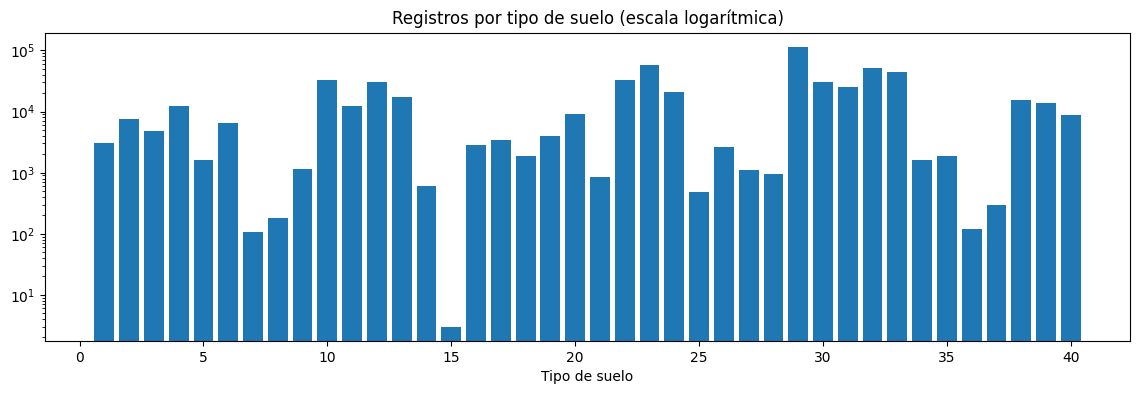

Suelos con menos de 0.1% de los registros:
Soil_Type_7     105
Soil_Type_8     179
Soil_Type_15      3
Soil_Type_25    474
Soil_Type_36    119
Soil_Type_37    298
dtype: int64


In [15]:
conteo_suelo = df[SUELOS].sum()
plt.figure(figsize=(14, 4))
plt.bar(range(1, 41), conteo_suelo.values)
plt.yscale('log')
plt.title('Registros por tipo de suelo (escala logarítmica)')
plt.xlabel('Tipo de suelo')
plt.show()

print("Suelos con menos de 0.1% de los registros:")
print(conteo_suelo[conteo_suelo < len(df) * 0.001])

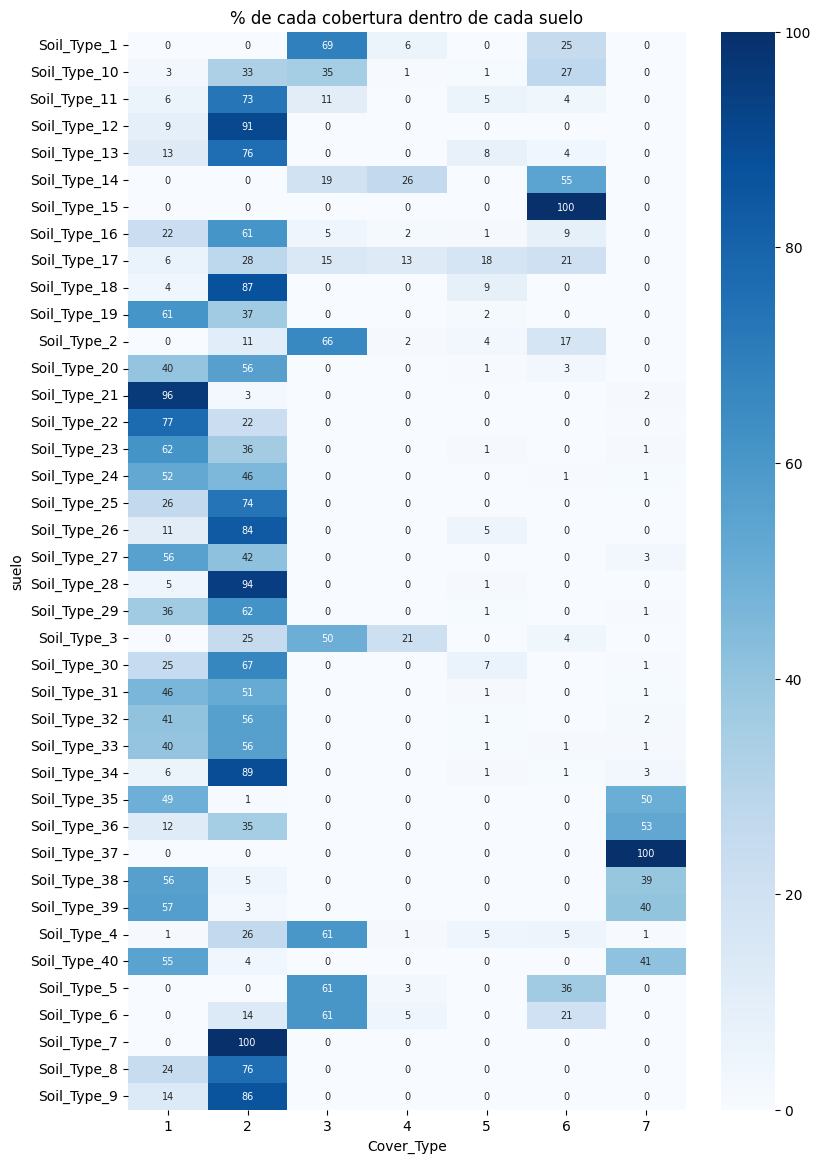

In [16]:
tabla_suelo = pd.crosstab(df['suelo'], df['Cover_Type'], normalize='index') * 100
plt.figure(figsize=(9, 14))
sns.heatmap(tabla_suelo, annot=True, fmt='.0f', cmap='Blues', annot_kws={'size': 7})
plt.title('% de cada cobertura dentro de cada suelo')
plt.show()

## Matriz de correlación
Las correlaciones entre las variables numéricas son moderadas. La más alta es entre el sombreado de las 9 am y el de las 3 pm (-0,78), seguida por Aspect con el sombreado de las 3 pm (0,65), la distancia horizontal con la vertical a hidrología (0,61) y el sombreado del mediodía con el de las 3 pm (0,59). Es lógico que los sombreados dependan de la orientación (Aspect) y de la pendiente, porque se calculan a partir de la luz del sol sobre el terreno. Las distancias a vías y a puntos de fuego casi no se relacionan con las de hidrología (0,07 y 0,05). Solo un par supera 0,7 en valor absoluto y ninguno llega a 0,8, así que no hay variables redundantes que haya que eliminar. Esta matriz mide solo relaciones lineales, y por eso se usan también modelos que captan relaciones no lineales.

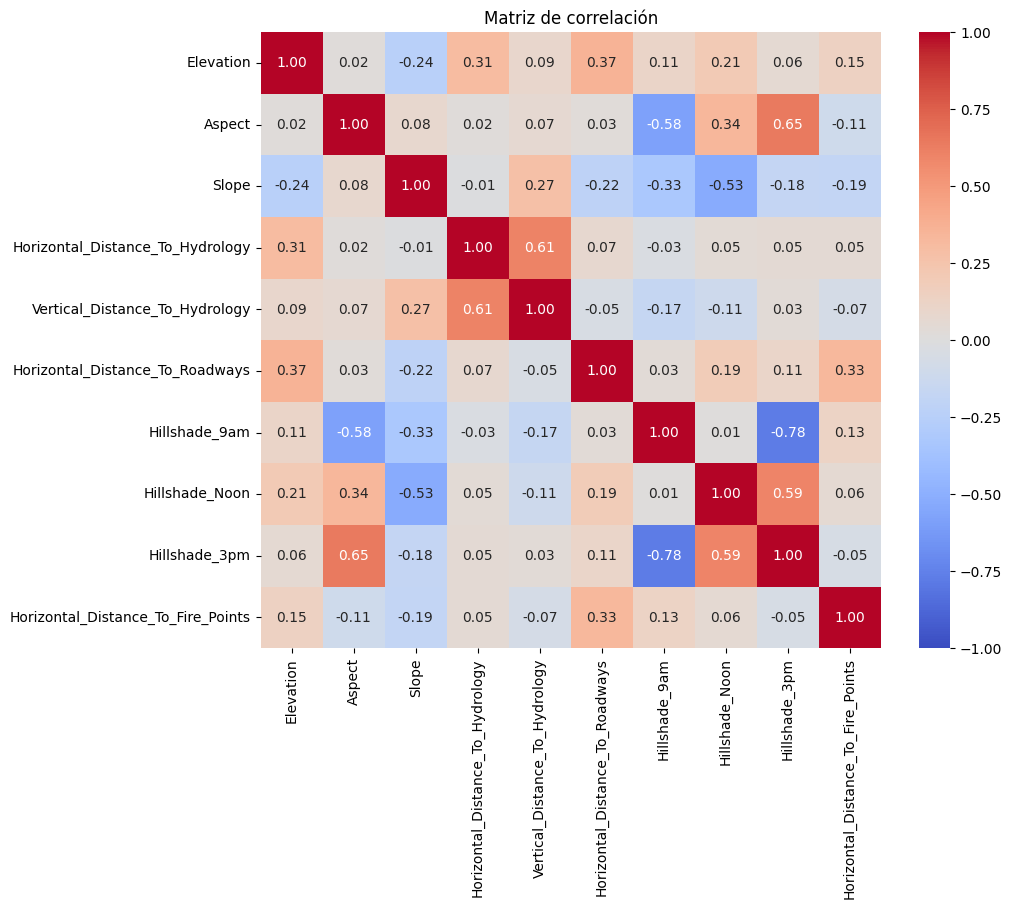

In [17]:
plt.figure(figsize=(10, 8))
sns.heatmap(df[NUMERICAS].corr(), annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Matriz de correlación')
plt.show()

## 3. Preprocesamiento


El dataset al no tener nulos y que las variables categóricas ya están en formato binario, no es necesario imputar, que es llenar vacíos, o codificar, que es pasar categorías o textos a números. Solo es necesario estandarizar las columnas numéricas, haciendo que todas tengan media 0 y desviación 1, evitando que alguna columna domine solo por tener números mas grandes, como las distancias de las carreteras.
Se divide el dataset en dos partes un 80% para el entrenamiento del modelo y un 20% para las pruebas.

Para evitar la fuga de información, el escalado se hace dentro de un Pipeline, así solo aprende la media y la desviación de los datos de entrenamiento y los datos de prueba no influyen en el modelo.

## Partición entrenamiento y prueba
80% entrenamiento y 20% prueba, estratificado por la clase.

In [18]:
from sklearn.model_selection import train_test_split

X = df[VARIABLES]
y = df['Cover_Type']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
print("Entrenamiento:", X_train.shape, "Prueba:", X_test.shape)

Entrenamiento: (464809, 54) Prueba: (116203, 54)


## Muestra

El trabajar con las 465 mil filas que trae el dataset puede hacer que modelos como KNN tarden demasiado en ejecutar debido a la gran cantidad de datos, por eso es necesario reducir la cantidad a una muestra de 100 mil registros, para que de está manera se reduzca el tiempo de ejecución manteniendo las proporciones originales.

In [19]:
X_m, _, y_m, _ = train_test_split(X_train, y_train, train_size=100000, stratify=y_train, random_state=42)

proporciones = pd.DataFrame({
    'completo': y.value_counts(normalize=True),
    'muestra': y_m.value_counts(normalize=True),
}).sort_index() * 100
proporciones.round(3)

,completo,muestra
Cover_Type,,
1,36.461,36.460
2,48.760,48.760
3,6.154,6.154
4,0.473,0.473
5,1.634,1.634
6,2.989,2.989
7,3.530,3.530


## Selección de variables

Se hace con un a muestra de 20 mil filas por motivos de eficiencia, ya que hacer la clasificación sobre muchos registros seria un proceso muy pesado, con 20 mil registros es una cantidad suficiente para obtener el ranking de importancia rápidamente, cuando se evalúan las variables, las que mas aportan son la elevación, las áreas silvestres y las distancias. Mientras que las que menos aportan son ciertos tipos de suelo por tener muy pocos registros activos, es decir, que casi todas sus filas están en 0, por su valor binario.

Elevation                             0.455787
Wilderness_Area_4                     0.144948
Horizontal_Distance_To_Roadways       0.094216
Horizontal_Distance_To_Fire_Points    0.068821
Wilderness_Area_1                     0.066963
Soil_Type_10                          0.064780
Slope                                 0.038527
Soil_Type_39                          0.033326
Hillshade_9am                         0.032727
Soil_Type_29                          0.029660
Soil_Type_38                          0.029379
Soil_Type_4                           0.028472
Soil_Type_12                          0.024989
Soil_Type_22                          0.024479
Horizontal_Distance_To_Hydrology      0.024311
Hillshade_3pm                         0.024266
Soil_Type_2                           0.024071
Soil_Type_23                          0.022171
Soil_Type_6                           0.019071
Soil_Type_40                          0.016580
dtype: float64


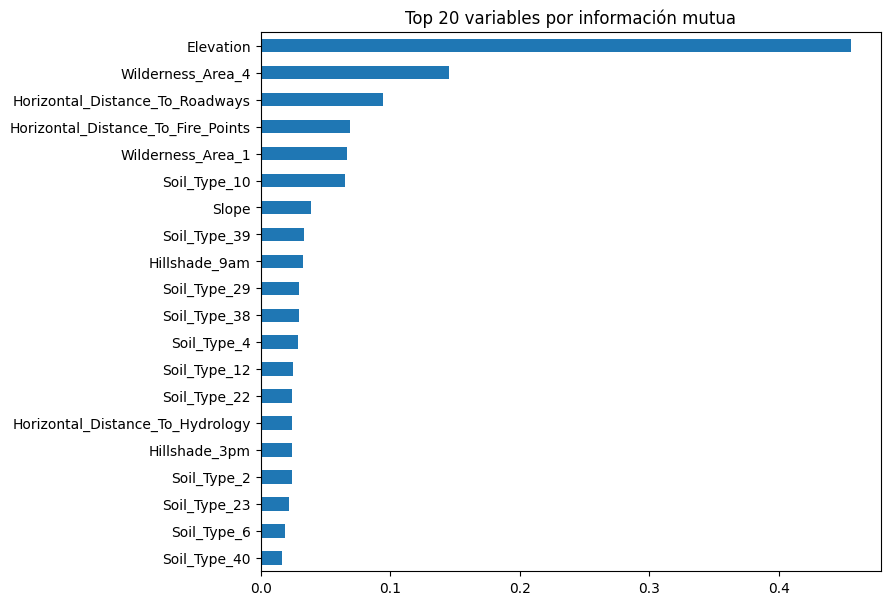

In [20]:
from sklearn.feature_selection import mutual_info_classif

X_mi, _, y_mi, _ = train_test_split(X_m, y_m, train_size=20000, stratify=y_m, random_state=42)
discretas = [col in AREAS + SUELOS for col in VARIABLES]
mi = mutual_info_classif(X_mi, y_mi, discrete_features=discretas, random_state=42)
mi = pd.Series(mi, index=VARIABLES).sort_values(ascending=False)
print(mi.head(20))

top20 = mi.head(20).index.tolist()

mi.head(20).sort_values().plot(kind='barh', figsize=(8, 7))
plt.title('Top 20 variables por información mutua')
plt.show()

## Escalado
Solo se escalan las numéricas, las binarias pasan igual.

In [21]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

escalado = ColumnTransformer([('num', StandardScaler(), NUMERICAS)], remainder='passthrough')

## 4. Componente supervisado

Juan Pablo Vasquez Tobon

En esta sección se busca predecir el tipo de cobertura forestal, que son 7 clases, a partir de las 54 variables. Se comparan tres modelos distintos y además una línea base que siempre responde la clase más frecuente, para tener contra qué comparar.

La regresión logística es el modelo lineal de referencia. Supone que las clases se pueden separar con fronteras lineales sobre las variables ya escaladas. Es rápida y los coeficientes se pueden interpretar, pero como en el EDA se vio que las clases se solapan bastante y que la elevación no se relaciona de forma lineal con la cobertura, lo más probable es que sea la que peor quede.

El KNN no asume ninguna forma de la frontera, clasifica cada registro según la clase que más se repite entre sus vecinos más cercanos. Necesita que las variables estén escaladas porque trabaja con distancias. Su limitación es el costo: no entrena, pero al momento de predecir tiene que comparar cada una de las 116.203 filas de prueba contra toda la muestra de entrenamiento, lo que lo hace lento.

El Random Forest promedia muchos árboles, cada uno entrenado con una muestra y unas variables distintas. Capta relaciones que no son lineales y también las combinaciones entre variables, por ejemplo elevación junto con área silvestre. No necesita escalado porque los árboles parten por umbrales y maneja bien las 40 variables binarias de suelo. Lo malo es que es más difícil de interpretar y ocupa más memoria.

La métrica principal es el F1 macro y no el accuracy, porque como se vio en el EDA el dataset está muy desbalanceado: las clases 1 y 2 se llevan más del 85 % de los registros y la clase 4 solo el 0,47 %. El F1 macro promedia el F1 de las siete clases dándoles el mismo peso, así que castiga a un modelo que ignore las clases pequeñas, mientras que con el accuracy ese mismo modelo se vería bien.

## Búsqueda de hiperparámetros
GridSearchCV con 3 particiones sobre 30.000 filas de la muestra.

Se usan 30.000 filas y 3 particiones para que la búsqueda no se demore demasiado, ya que cada combinación entrena tres modelos. Después el ganador de cada familia se vuelve a entrenar con la muestra completa de 100.000.

En la regresión logística se probó C en 0,1, 1 y 10, que controla qué tanto se regulariza, y class_weight en None y en balanced, que le sube el peso a las clases pequeñas. Quedó C igual a 10 sin balanceo, con un F1 macro de validación de 0,5512. El balanceo no ayudó porque subía el recall de las clases raras pero dañaba las grandes, y al final el promedio quedaba más bajo.

En el KNN se probó n_neighbors en 1, 3, 5, 9 y 15 y ganó k igual a 1, con 0,7004. Que gane el vecino más cercano muestra que las clases están muy mezcladas: apenas se amplía la vecindad entran vecinos de las clases grandes y las pequeñas se pierden.

En el Random Forest se probó max_features en sqrt y 0.3 y min_samples_leaf en 1 y 3. Quedó max_features de 0.3 con min_samples_leaf de 1, con un F1 macro de 0,7646, el mejor de los tres. Mirar más variables en cada corte y dejar las hojas sin podar le sirve para alcanzar a separar las clases minoritarias.

In [22]:
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier

X_gs, _, y_gs, _ = train_test_split(X_m, y_m, train_size=30000, stratify=y_m, random_state=42)

# regresión logística
pipe_lr = Pipeline([('escalado', escalado), ('modelo', LogisticRegression(max_iter=2000))])
gs_lr = GridSearchCV(pipe_lr, {'modelo__C': [0.1, 1, 10], 'modelo__class_weight': [None, 'balanced']},
                     scoring='f1_macro', cv=3)
gs_lr.fit(X_gs, y_gs)
print("Regresión logística:", gs_lr.best_params_, round(gs_lr.best_score_, 4))

# KNN
pipe_knn = Pipeline([('escalado', escalado), ('modelo', KNeighborsClassifier())])
gs_knn = GridSearchCV(pipe_knn, {'modelo__n_neighbors': [1, 3, 5, 9, 15]}, scoring='f1_macro', cv=3)
gs_knn.fit(X_gs, y_gs)
print("KNN:", gs_knn.best_params_, round(gs_knn.best_score_, 4))

# random forest
rf = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
gs_rf = GridSearchCV(rf, {'max_features': ['sqrt', 0.3], 'min_samples_leaf': [1, 3]}, scoring='f1_macro', cv=3)
gs_rf.fit(X_gs, y_gs)
print("Random Forest:", gs_rf.best_params_, round(gs_rf.best_score_, 4))

Regresión logística: {'modelo__C': 10, 'modelo__class_weight': None} 0.5512


KNN: {'modelo__n_neighbors': 1} 0.7004


Random Forest: {'max_features': 0.3, 'min_samples_leaf': 1} 0.7646


## Entrenamiento y comparación
Los modelos se entrenan con la muestra de 100.000 y se evalúan con todo el conjunto de prueba.

El orden es el mismo de la búsqueda de hiperparámetros pero con mejores resultados, porque ahora cada modelo se entrena con 100.000 filas. La línea base queda en 0,4876 de accuracy y 0,0937 de F1 macro, la regresión logística en 0,7234 y 0,5354, el KNN en 0,8908 y 0,8215, y el Random Forest en 0,9222 y 0,8752.

El mejor es el Random Forest. Frente a la línea base multiplica el F1 macro casi por nueve, y frente a la regresión logística le saca 34 puntos. Esa diferencia tan grande con el modelo lineal confirma lo que mostraba el EDA: las fronteras entre coberturas no son lineales y hay combinaciones entre elevación, área silvestre y tipo de suelo que un modelo lineal no alcanza a representar. El KNN queda en el medio, aunque es el más lento al predecir.

La diferencia entre accuracy y F1 macro se nota sobre todo en la línea base, que acierta el 48,8 % de las veces solo por responder siempre la clase 2, pero tiene un F1 macro de 0,09 porque falla por completo en las otras seis clases. En los modelos buenos la distancia se achica, 0,9222 contra 0,8752 en el Random Forest, y lo que queda de diferencia es justamente lo que les cuestan las clases pequeñas.

In [23]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay

modelos = {
    'Línea base': DummyClassifier(strategy='most_frequent'),
    'Regresión logística': gs_lr.best_estimator_,
    'KNN': gs_knn.best_estimator_,
    'Random Forest': gs_rf.best_estimator_,
}

resultados = []
predicciones = {}
for nombre, modelo in modelos.items():
    modelo.fit(X_m, y_m)
    pred = modelo.predict(X_test)
    predicciones[nombre] = pred
    resultados.append([nombre, accuracy_score(y_test, pred), f1_score(y_test, pred, average='macro')])

resultados = pd.DataFrame(resultados, columns=['modelo', 'accuracy', 'f1_macro'])
resultados

,modelo,accuracy,f1_macro
0,Línea base,0.487604,0.093651
1,Regresión logística,0.723424,0.535408
2,KNN,0.890769,0.821451
3,Random Forest,0.922162,0.875160


## Reporte por clase y matriz de confusión
El mejor modelo es el Random Forest entrenado con la muestra de 100.000.

El reporte muestra que el modelo no responde igual de bien en todas las clases. Las grandes van muy bien: Picea/Abeto queda con 0,92 de F1 y Pino contorta con 0,93. También quedan altas Pino ponderosa y Krummholz, las dos con 0,92, que aunque tienen menos registros están en zonas del terreno bien separadas.

La peor clase es el Álamo temblón, con 0,76 de F1. La precisión es de 0,92 pero el recall es de solo 0,65, o sea que cuando el modelo dice que es álamo temblón casi siempre acierta, pero se le escapa un tercio de los casos reales. En la matriz de confusión normalizada se ve a dónde se van: el 31 % de los álamos temblones reales se predicen como Pino contorta. Después sigue Álamo/Sauce con 0,82 de F1 y recall de 0,78, que es la clase más pequeña con 549 filas en prueba y de la cual el 20 % se predice como Pino ponderosa. El Abeto Douglas queda en 0,86 y se confunde un 12 % con Pino ponderosa.

Entre las clases grandes la confusión más marcada es que el 9 % de Picea/Abeto se predice como Pino contorta. Todo esto coincide con el EDA, donde se vio que las parejas 1 y 2, y 3 y 6 comparten rango de elevación y aparecen en las mismas áreas silvestres. Las clases 4, 5 y 6 además son las que menos registros tienen, así que el modelo cuenta con menos ejemplos para aprenderlas.

Mejor modelo: Random Forest
                precision    recall  f1-score   support

   Picea/Abeto       0.93      0.90      0.92     42368
 Pino contorta       0.92      0.95      0.93     56661
Pino ponderosa       0.90      0.93      0.92      7151
   Álamo/Sauce       0.86      0.78      0.82       549
 Álamo temblón       0.92      0.65      0.76      1899
 Abeto Douglas       0.89      0.83      0.86      3473
     Krummholz       0.95      0.90      0.92      4102

      accuracy                           0.92    116203
     macro avg       0.91      0.85      0.88    116203
  weighted avg       0.92      0.92      0.92    116203



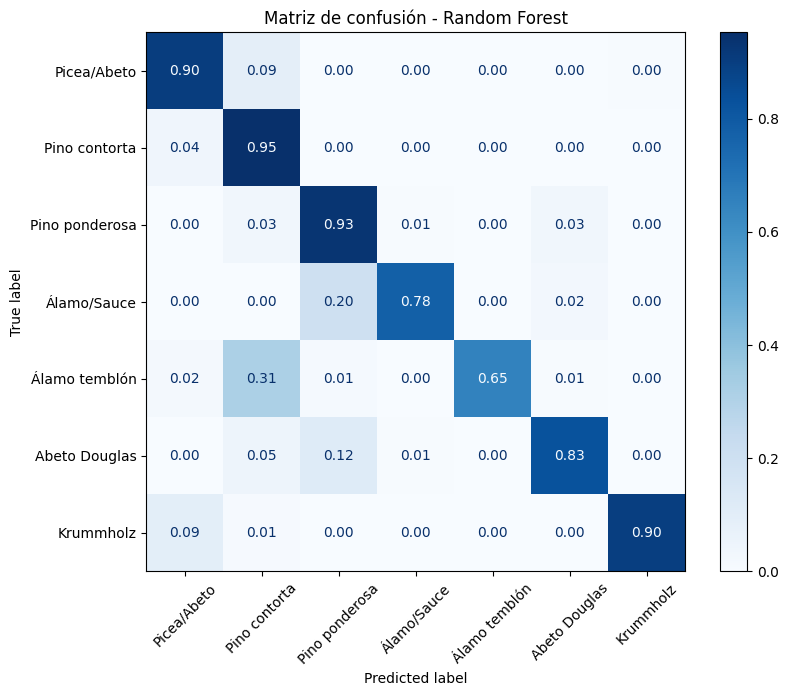

In [24]:
mejor = resultados.iloc[1:].sort_values('f1_macro').iloc[-1]['modelo']
print("Mejor modelo:", mejor)
print(classification_report(y_test, predicciones[mejor], target_names=list(CLASES.values())))

fig, ax = plt.subplots(figsize=(9, 7))
ConfusionMatrixDisplay.from_predictions(y_test, predicciones[mejor], normalize='true',
                                        display_labels=list(CLASES.values()),
                                        values_format='.2f', cmap='Blues', ax=ax)
plt.xticks(rotation=45)
plt.title('Matriz de confusión - ' + mejor)
plt.show()

## Importancia de las variables
Importancia que da el Random Forest.

La variable más importante de lejos es la elevación, que se lleva cerca de la cuarta parte de toda la importancia, más del doble que la que le sigue. Después vienen la distancia horizontal a vías y la distancia a puntos de fuego, luego las dos distancias a hidrología, el aspecto, los tres sombreados y la pendiente. Es decir que las 10 variables numéricas concentran casi toda la importancia.

De las 44 variables binarias la única que entra alto es Wilderness_Area_4. Los tipos de suelo quedan todos con valores muy pequeños y apenas se asoman uno o dos en las primeras quince posiciones.

Esto coincide con el EDA y con la información mutua de la sección 3, donde también salieron de primeras Elevation con 0,456, Wilderness_Area_4 con 0,145, la distancia a vías con 0,094 y la distancia a puntos de fuego con 0,069. La diferencia es que la información mutua subía más algunos tipos de suelo, como el 10, el 39, el 29 y el 38, porque mide cada variable por aparte. El Random Forest en cambio reparte esa información entre las numéricas que ya separan lo mismo: un tipo de suelo suele estar asociado a un rango de elevación, entonces una vez el árbol corta por elevación el suelo ya casi no aporta.

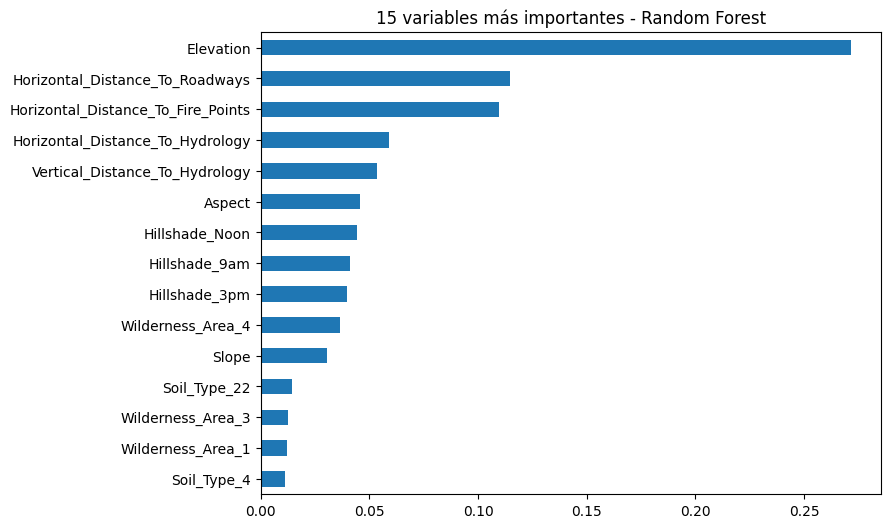

In [25]:
importancia = pd.Series(gs_rf.best_estimator_.feature_importances_, index=VARIABLES)
importancia.sort_values().tail(15).plot(kind='barh', figsize=(8, 6))
plt.title('15 variables más importantes - Random Forest')
plt.show()

## Curva de aprendizaje
Se entrena el Random Forest con diferentes tamaños para ver si usar todo el dataset mejora el resultado. El último tamaño es todo el entrenamiento.

Con 10.000 filas el F1 macro en prueba es de 0,7038, con 25.000 sube a 0,7760, con 50.000 a 0,8287, con 100.000 a 0,8752, con 200.000 a 0,9101 y con las 464.809 filas del entrenamiento completo llega a 0,9397.

La curva sigue subiendo hasta el final y no se aplana, así que al modelo todavía le sirven más datos y con un dataset más grande seguiría mejorando un poco. De todas formas las ganancias se van achicando: de 10.000 a 25.000 sube 7 puntos, de 100.000 a 200.000 sube 3,5 y de 200.000 a 464.809 sube solo 3, aun usando más del doble de filas.

Entonces la muestra de 100.000 sí valió la pena para la parte de comparar modelos y buscar hiperparámetros, que es donde cada modelo se entrena muchas veces, porque deja el F1 macro en 0,8752, a 6 puntos del máximo, y hace que esa parte corra en minutos y no en horas. Para el modelo final, que se entrena una sola vez, sí conviene usar todo el entrenamiento.

10000 filas -> F1 macro: 0.7038


25000 filas -> F1 macro: 0.776


50000 filas -> F1 macro: 0.8287


100000 filas -> F1 macro: 0.8752


200000 filas -> F1 macro: 0.9101


464809 filas -> F1 macro: 0.9397


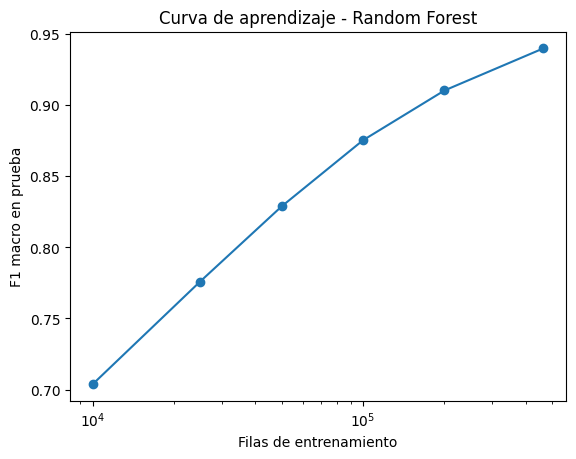

In [26]:
tamanos = [10000, 25000, 50000, 100000, 200000, len(X_train)]
f1_tamanos = []
for n in tamanos:
    if n < len(X_train):
        X_n, _, y_n, _ = train_test_split(X_train, y_train, train_size=n, stratify=y_train, random_state=42)
    else:
        X_n, y_n = X_train, y_train
    modelo = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1, **gs_rf.best_params_)
    modelo.fit(X_n, y_n)
    f1 = f1_score(y_test, modelo.predict(X_test), average='macro')
    f1_tamanos.append(f1)
    print(n, "filas -> F1 macro:", round(f1, 4))

plt.plot(tamanos, f1_tamanos, marker='o')
plt.xscale('log')
plt.xlabel('Filas de entrenamiento')
plt.ylabel('F1 macro en prueba')
plt.title('Curva de aprendizaje - Random Forest')
plt.show()

## Modelo final
El último modelo de la curva quedó entrenado con todo el entrenamiento. Se evalúa por clase.

El modelo final es el Random Forest con max_features de 0.3 y min_samples_leaf de 1, entrenado con las 464.809 filas de entrenamiento. Queda con 0,96 de accuracy y 0,9397 de F1 macro, contra 0,9222 y 0,8752 del mismo modelo entrenado con la muestra de 100.000.

Lo interesante es dónde está esa mejora. Las clases grandes suben poco porque ya estaban altas: Picea/Abeto pasa de 0,92 a 0,96 de F1 y Pino contorta de 0,93 a 0,97. Las que más ganan son las pequeñas. El Álamo temblón pasa de 0,76 a 0,89 de F1 y su recall sube de 0,65 a 0,84, el Álamo/Sauce pasa de 0,82 a 0,89 con el recall de 0,78 a 0,87, y el Abeto Douglas pasa de 0,86 a 0,93 con el recall de 0,83 a 0,91.

En la matriz de confusión se ve lo mismo: la fuga de álamo temblón hacia Pino contorta baja del 31 % al 14 % y la de Álamo/Sauce hacia Pino ponderosa baja del 20 % al 10 %. Tiene sentido, porque al multiplicar por más de cuatro las filas de entrenamiento las clases minoritarias pasan de unos pocos cientos de ejemplos a varios miles, que era lo que les faltaba. Aun así siguen siendo las clases más débiles del modelo, o sea que más datos alivian el desbalance pero no lo quitan.

                precision    recall  f1-score   support

   Picea/Abeto       0.97      0.96      0.96     42368
 Pino contorta       0.96      0.98      0.97     56661
Pino ponderosa       0.95      0.97      0.96      7151
   Álamo/Sauce       0.91      0.87      0.89       549
 Álamo temblón       0.95      0.84      0.89      1899
 Abeto Douglas       0.95      0.91      0.93      3473
     Krummholz       0.97      0.96      0.97      4102

      accuracy                           0.96    116203
     macro avg       0.95      0.93      0.94    116203
  weighted avg       0.96      0.96      0.96    116203



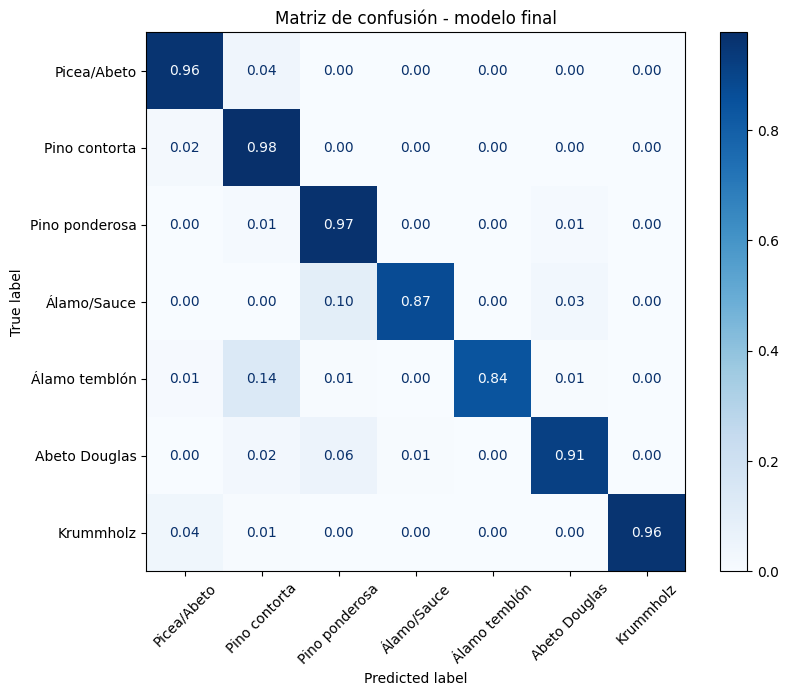

In [27]:
modelo_final = modelo
pred_final = modelo_final.predict(X_test)
print(classification_report(y_test, pred_final, target_names=list(CLASES.values())))

fig, ax = plt.subplots(figsize=(9, 7))
ConfusionMatrixDisplay.from_predictions(y_test, pred_final, normalize='true',
                                        display_labels=list(CLASES.values()),
                                        values_format='.2f', cmap='Blues', ax=ax)
plt.xticks(rotation=45)
plt.title('Matriz de confusión - modelo final')
plt.show()

## Selección de variables y PCA en el modelo
Mismo Random Forest con menos variables y con PCA (95% de la varianza).

Para comparar en igualdad de condiciones las cuatro pruebas se entrenan con la misma muestra de 100.000 filas. Con las 54 variables el F1 macro es de 0,8752, con las 20 mejores de información mutua baja a 0,8662, con solo las 10 numéricas baja a 0,8261 y con PCA queda en 0,8353.

Quitar variables sí cuesta, pero poco: con el top 20 se pierde menos de un punto usando apenas un tercio de las columnas, lo que confirma que entre las 54 variables hay información repetida y que los 40 tipos de suelo aportan muy poco cada uno. Si se dejan solo las 10 numéricas la caída ya es de 5 puntos, o sea que las áreas silvestres y los suelos no son decisivos pero sí ayudan.

El PCA no sirvió en este caso. Necesita 43 componentes para conservar el 95 % de la varianza, así que casi no reduce nada, de 54 a 43, y aun así pierde 4 puntos de F1 macro. Esto pasa porque el PCA busca las direcciones donde hay más varianza y no las que separan mejor las clases, y además mezcla todas las variables en combinaciones lineales, con lo que el Random Forest pierde los cortes limpios por elevación o por área silvestre que son los que le sirven. Con variables binarias como los tipos de suelo tampoco tiene mucho sentido aplicarlo. En conclusión, para este problema es mejor quedarse con las variables originales, y si se necesitara un modelo más liviano convendría usar el top 20 de información mutua antes que el PCA.

In [28]:
from sklearn.decomposition import PCA

rf_base = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1, **gs_rf.best_params_)

conjuntos = {
    'Todas (54)': VARIABLES,
    'Top 20 información mutua': top20,
    'Solo numéricas (10)': NUMERICAS,
}
for nombre, cols in conjuntos.items():
    rf_base.fit(X_m[cols], y_m)
    pred = rf_base.predict(X_test[cols])
    print(nombre, "-> F1 macro:", round(f1_score(y_test, pred, average='macro'), 4))

pipe_pca = Pipeline([('escalado', StandardScaler()), ('pca', PCA(n_components=0.95)), ('modelo', rf_base)])
pipe_pca.fit(X_m, y_m)
pred = pipe_pca.predict(X_test)
print("PCA", pipe_pca.named_steps['pca'].n_components_, "componentes -> F1 macro:",
      round(f1_score(y_test, pred, average='macro'), 4))

Todas (54) -> F1 macro: 0.8752


Top 20 información mutua -> F1 macro: 0.8662


Solo numéricas (10) -> F1 macro: 0.8261


PCA 43 componentes -> F1 macro: 0.8353
